# Get diaObjectIds classified by ALeRCE as SN.

This notebooks saves in your Google Drive a csv file with the following columns: `oid, ra, dec, ndiasources, class_name, probability`.

*   `class_name = {'SN'}`
*   `probability >= 0.8`
*   `ndiasources > 1 `

The query takes a little bit of time ~5min








# Install

In [ ]:
! pip install alerce
! pip install pyvo

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 14.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 4.9 MB/s eta 0:00:00


# Imports

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pyvo as vo
import os
import time
import threading
from concurrent.futures import ThreadPoolExecutor

# Initalize Alerce client

In [ ]:
from alerce.core import Alerce
alerce = Alerce()

# Initialize TAP service

In [ ]:
tap_service_url = "https://tap.alerce.online/tap"
service = vo.dal.TAPService(tap_service_url)

## query the top 200K objects that are classified as SN by alerce with a probability >= 0.8

200K is max amount allowed per query


In [ ]:
# Write the ADQL query
query = """
      SELECT DISTINCT TOP 200000
          obj.oid, obj.ra, obj.dec, obj.ndiasources, tax.class_name, prob.probability
      FROM alerce_tap.lsst_dia_object AS obj
      JOIN alerce_tap.probability AS prob ON obj.oid = prob.oid
      JOIN alerce_tap.taxonomy AS tax ON prob.class_id = tax.class_id
      WHERE tax.class_name = 'SN'
        AND prob.probability >= 0.8 AND prob.ranking=1
        AND obj.ndiasources > 1 AND tax.classifier_id=2
"""

# Execute the synchronous or asynchronous TAP job
df_sn = service.search(query).to_table().to_pandas()

In [ ]:
df_sn.shape

(7976, 6)

In [ ]:
df_sn

,oid,ra,dec,ndiasources,class_name,probability
0,170019695992242795,52.823847,-29.691600,7,SN,0.991934
1,170019695992242795,52.823847,-29.691600,7,SN,0.994920
2,170019696008495213,53.169752,-29.185676,13,SN,0.974966
3,170019696046768167,54.237795,-27.670760,7,SN,0.910110
4,170019696046768167,54.237795,-27.670760,7,SN,0.973086
...,...,...,...,...,...,...
7971,314051320318263356,56.862116,-48.948286,123,SN,0.889471
7972,314051320443043860,62.669726,-47.693403,62,SN,0.916036
7973,314051320803229791,51.869484,-28.895136,9,SN,0.987434
7974,314051320940068947,52.588064,-28.315550,8,SN,0.830271


In [ ]:
df_all = pd.concat([df_sn])


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
path_save = "/content/drive/MyDrive/hackathon_colombia_oct_2026"

There are duplicated oid, some alerce parameter I'm not taking into account when doing the query, but it's ok, it's not so bad, I will just drop them

In [ ]:
df_all = df_all.drop_duplicates(subset=['oid']).reset_index(drop=True)

In [ ]:
df_all.shape

(6653, 6)

### SAVE CSV FILE

uncomment to save csv file. Be aware of changing the `path_save` (a few line above) to your like, same with the name of the file

In [ ]:
# df_all.to_csv(os.path.join(path_save,'alerce_sn_classifier2_probgt08.csv.gz'), index=False, compression='gzip')

## Some plots

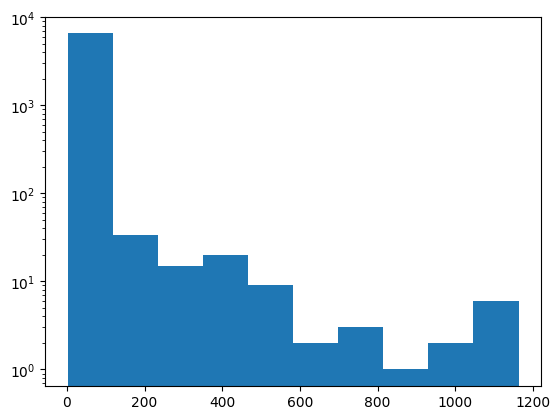

In [ ]:
plt.hist(df_all['ndiasources']);
plt.yscale('log')

In [ ]:
df_all['class_name'].value_counts()


,count
class_name,
SN,6653


In [ ]:
df_all.query('ndiasources > 2')['class_name'].value_counts()

,count
class_name,
SN,4088


In [ ]:
df_all.query('ndiasources > 50')['class_name'].value_counts()

,count
class_name,
SN,206
